# 07 - Assess Temporal Drift

Name: Usha Oudeacoumar
Student ID: 20057009
Email: 20057009@mydbs.ie

This is the main experiment of the whole project. The two baseline models were
trained on 2011-2014 and frozen (not touched since notebook 05). This notebook
takes those exact same frozen models and applies them, unchanged, to each later
year one at a time (2015, 2016, 2017, 2018, 2019) and works out AUROC, Brier
score, calibration intercept, calibration slope and ECE for each year. Then it
plots these over time to see if the calibration gets worse as the model gets
older (this is testing hypothesis H1 from the project spec). The model is NOT
retrained or updated anywhere in this notebook.

In [1]:
import sys
sys.path.append(".")
import os
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from utils import PROC_DIR, MODELS_DIR, OUT_TABLES, OUT_FIGS, load_json, get_all_metrics

os.makedirs(OUT_TABLES, exist_ok=True)
os.makedirs(OUT_FIGS, exist_ok=True)

cfg = load_json("../configs/study_config.json")
eval_years = cfg["eval_years"]

log_reg = joblib.load(os.path.join(MODELS_DIR, "log_reg_model.pkl"))
gb = joblib.load(os.path.join(MODELS_DIR, "gb_model.pkl"))
feat_cols = joblib.load(os.path.join(MODELS_DIR, "feat_cols.pkl"))

eval_df = pd.read_csv(os.path.join(PROC_DIR, "eval_data.csv"))
eval_df.shape

(75154, 92)

In [2]:
# run both frozen models on every eval year, one year at a time, and keep the metrics
drift_rows = []
preds_by_year = {}

for yr in eval_years:
    yr_df = eval_df[eval_df["yr"] == yr]
    X_yr, y_yr = yr_df[feat_cols], yr_df["admit"]

    p_log_reg = log_reg.predict_proba(X_yr)[:, 1]
    p_gb = gb.predict_proba(X_yr)[:, 1]
    preds_by_year[yr] = {"y": y_yr.values, "log_reg": p_log_reg, "gb": p_gb}

    m1 = get_all_metrics(y_yr, p_log_reg)
    m2 = get_all_metrics(y_yr, p_gb)
    drift_rows.append({"yr": yr, "model": "logistic_regression", "n": len(yr_df), **m1})
    drift_rows.append({"yr": yr, "model": "gradient_boosting", "n": len(yr_df), **m2})

drift_table = pd.DataFrame(drift_rows)
drift_table

,yr,model,n,auroc,brier,cal_intercept,cal_slope,ece
0,2015,logistic_regression,16393,0.813589,0.080459,-0.284415,0.984055,0.021988
1,2015,gradient_boosting,16393,0.821926,0.078495,-0.180894,1.044735,0.020618
2,2016,logistic_regression,15242,0.809096,0.078984,-0.323017,0.992952,0.026389
3,2016,gradient_boosting,15242,0.816619,0.077736,-0.229849,1.047231,0.025151
4,2017,logistic_regression,12793,0.797547,0.089752,-0.213976,0.945089,0.012770
5,2017,gradient_boosting,12793,0.807454,0.087589,-0.087161,1.022471,0.011168
6,2018,logistic_regression,15827,0.792851,0.099716,-0.091435,0.955404,0.008709
7,2018,gradient_boosting,15827,0.799184,0.098327,-0.003746,1.004207,0.003225
8,2019,logistic_regression,14899,0.797870,0.093942,-0.182984,0.979252,0.014852
9,2019,gradient_boosting,14899,0.805235,0.092004,-0.081070,1.040731,0.013348


In [3]:
drift_table.to_csv(os.path.join(OUT_TABLES, "07_temporal_drift_metrics.csv"), index=False)

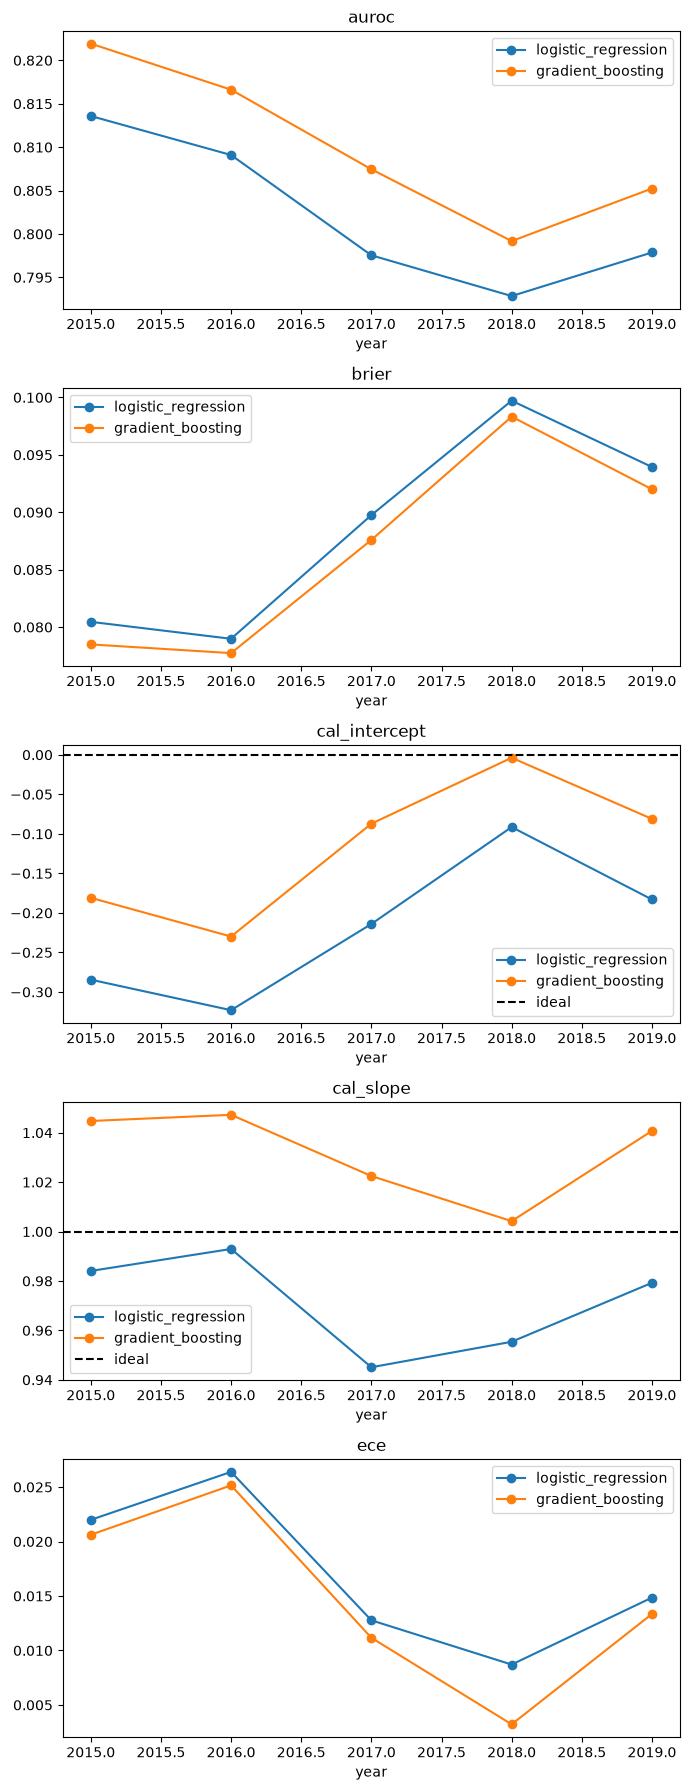

In [4]:
# plot each metric over the years, one line per model, so we can see the drift
metrics_to_plot = ["auroc", "brier", "cal_intercept", "cal_slope", "ece"]
perfect_val = {"auroc": None, "brier": None, "cal_intercept": 0, "cal_slope": 1, "ece": None}

fig, axes = plt.subplots(len(metrics_to_plot), 1, figsize=(7, 18))

for ax, metric in zip(axes, metrics_to_plot):
    for model_name in ["logistic_regression", "gradient_boosting"]:
        sub = drift_table[drift_table["model"] == model_name]
        ax.plot(sub["yr"], sub[metric], marker="o", label=model_name)
    if perfect_val[metric] is not None:
        ax.axhline(perfect_val[metric], color="black", linestyle="--", label="ideal")
    ax.set_title(metric)
    ax.set_xlabel("year")
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_FIGS, "07_drift_over_time.png"))
plt.show()

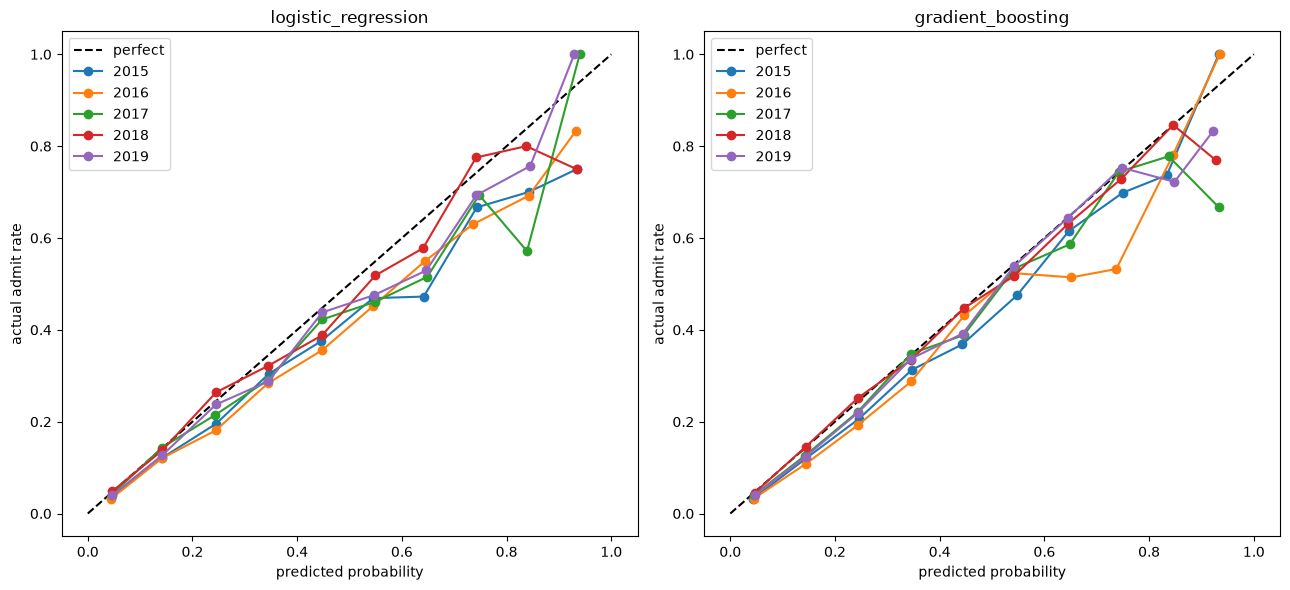

In [5]:
# calibration curve for every eval year, same binning idea as notebook 06
def calibration_points(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    mean_pred = []
    mean_true = []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (y_prob > lo) & (y_prob <= hi) if i > 0 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() == 0:
            continue
        mean_pred.append(y_prob[mask].mean())
        mean_true.append(np.asarray(y_true)[mask].mean())
    return mean_pred, mean_true

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, model_key, model_name in zip(axes, ["log_reg", "gb"], ["logistic_regression", "gradient_boosting"]):
    ax.plot([0, 1], [0, 1], "k--", label="perfect")
    for yr in eval_years:
        y_yr = preds_by_year[yr]["y"]
        p_yr = preds_by_year[yr][model_key]
        pred_pts, true_pts = calibration_points(y_yr, p_yr)
        ax.plot(pred_pts, true_pts, marker="o", label=str(yr))
    ax.set_title(model_name)
    ax.set_xlabel("predicted probability")
    ax.set_ylabel("actual admit rate")
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_FIGS, "07_calibration_curves_by_year.png"))
plt.show()